# Opción 3 — Rectificación al plano métrico + camino geodésico + eje con extensión recta

La opción 2 busca el camino en píxeles y sólo proyecta a cm los puntos del resultado: con perspectiva, el camino de costo mínimo y los extremos geodésicos no son los del plano real. Acá se **rectifica la máscara** con `cv2.warpPerspective` usando la homografía del ArUco (`H`, ID 17, 5 cm), de modo que 1 px = 1/`res` cm de forma uniforme, y recién ahí se hace todo:

1. Máscara limpia → `warpPerspective` a un lienzo métrico (`RES_PX_POR_CM`, con tope `LADO_MAX_PX`).
2. Extremos A/B por diámetro geodésico, camino con costo `1/(dt+1)**p`, suavizado.
3. Opción 2b sobre la máscara rectificada: eje + extensión recta hasta la punta del lóbulo más largo (`LT_axial_cm`).
4. Los puntos se llevan de vuelta a la imagen original con la inversa de la rectificación para dibujar.

El CSV incluye también los valores de la opción 2 (`*_op2`, camino en píxeles + homografía) para comparar. Limitación que se mantiene: se supone que el pez está en el mismo plano que el ArUco.

In [1]:
%pip install -q numpy scipy opencv-contrib-python scikit-image matplotlib pandas ultralytics

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt
from scipy.signal import savgol_filter
from scipy.interpolate import splprep, splev
from skimage.graph import MCP_Geometric, route_through_array

import fish_length_utils as U

# ---------------- parámetros ----------------
N_IMAGENES = None            # None = todas las imágenes de examples/; o un entero (primeras N)
CARPETA_IMAGENES = U.EXAMPLES_DIR
WEIGHTS = U.WEIGHTS
CONF, IMGSZ = U.CONF, U.IMGSZ
ARUCO_ID, TAMANO_ARUCO_CM = U.ARUCO_ID, U.TAMANO_ARUCO_CM
P_COSTO = 2                  # exponente p del costo 1/(dt+1)**p (probar 1, 2 y 3)
P_COMPARAR = (1, 2, 3)       # valores de p que se comparan en el CSV (el principal es P_COSTO)
SUAVIZADO = "savgol"         # "savgol" o "spline"
SUAV_FRAC = 0.15             # savgol: ventana = SUAV_FRAC * n_puntos del camino (impar, >= 11)
SPLINE_S_PX = 2.0            # spline: s = SPLINE_S_PX**2 * n_puntos (desvío cuadrático medio permitido, px)
LADO_MAX_PX = 1200           # reescala la máscara recortada si su lado mayor lo supera; None = sin reescalar
# ---- opción 2b (eje + extensión recta): fracciones de la longitud del camino
F_INI, F_REF, F_FIN = 0.55, 0.70, 0.80   # dirección del eje = punto(F_FIN) - punto(F_INI); origen O = punto(F_REF)
F_REF_DOBLADA = 0.60                     # F_REF alternativo si la cola está doblada
ANGULO_COLA_MAX = 30                     # grados entre el eje y el tramo 80 %-100 % para marcar cola_doblada
# ---- opción 3: rectificación al plano métrico
RES_PX_POR_CM = 20           # resolución de la máscara rectificada (px/cm); se reduce sola si supera LADO_MAX_PX
MARGEN_CM = 1.0              # margen alrededor del pez en la imagen rectificada
EXTENSION_MAX_CM = 300       # si el pez proyectado mide más que esto la homografía es degenerada: se omite el pez
SALIDA_IMGS = Path("outputs/opcion3")
SALIDA_CSV = Path("outputs/resultados_opcion3.csv")

## Funciones

Las de la opción 2 (`preparar_mascara`, geodésica, suavizado, `lt_axial`, `medir_geodesica`) se reutilizan tal cual, para comparar; las nuevas son `rectificar_mascara` y `medir_rectificada`.

In [3]:
def preparar_mascara(mask, px_por_cm, lado_max=LADO_MAX_PX):
    """Limpia la máscara, la recorta a su bounding box (con margen de 2 px) y, si el lado mayor supera `lado_max`,
    la reescala. Devuelve (m_bool, px_por_cm_esc, escala, (x0, y0)). Las coordenadas del recorte reescalado se llevan
    a la imagen original con: p_orig = p / escala + (x0, y0).  px_por_cm_esc = px_por_cm * escala."""
    m = U.limpiar_mascara(mask)
    ys, xs = np.nonzero(m)
    x0, y0 = max(xs.min() - 2, 0), max(ys.min() - 2, 0)
    m = m[y0:ys.max() + 3, x0:xs.max() + 3]
    escala = 1.0
    if lado_max and max(m.shape) > lado_max:
        escala = lado_max / max(m.shape)
        m = cv2.resize(m, None, fx=escala, fy=escala, interpolation=cv2.INTER_NEAREST)
    return m > 0, px_por_cm * escala, escala, (x0, y0)


def mas_lejano_geodesico(mask_bool, origen):
    """Punto (fila, col) de la máscara geodésicamente más lejano de `origen` (costo 1 dentro, inf fuera)."""
    costo = np.where(mask_bool, 1.0, np.inf)
    acum, _ = MCP_Geometric(costo, fully_connected=True).find_costs([tuple(origen)])
    acum = np.where(np.isfinite(acum), acum, -1)
    return np.unravel_index(np.argmax(acum), acum.shape)


def extremos_geodesicos(mask_bool):
    """Extremos A y B por diámetro geodésico (doble barrido). Devuelve (A, B) como (fila, col)."""
    ys, xs = np.nonzero(mask_bool)
    k = len(ys) // 2                      # un píxel cualquiera de la máscara
    A = mas_lejano_geodesico(mask_bool, (ys[k], xs[k]))
    B = mas_lejano_geodesico(mask_bool, A)
    return tuple(int(v) for v in A), tuple(int(v) for v in B)


def camino_centrado(mask_bool, A, B, p=P_COSTO):
    """Camino mínimo A→B con costo 1/(dt+1)**p dentro de la máscara (inf fuera). Devuelve array (N, 2) en (x, y)."""
    dt = distance_transform_edt(mask_bool)
    costo = np.where(mask_bool, 1.0 / (dt + 1.0) ** p, np.inf)
    ruta, _ = route_through_array(costo, A, B, fully_connected=True, geometric=True)
    ruta = np.asarray(ruta, dtype=np.float64)
    return ruta[:, ::-1]                  # (fila, col) -> (x, y)


def suavizar_camino(xy, metodo=SUAVIZADO, frac=SUAV_FRAC, s_px=SPLINE_S_PX):
    """Suaviza el camino (N, 2) manteniendo los extremos fijos. 'savgol' (ventana relativa, polinomio de grado 3)
    o 'spline' (spline cúbica suavizada)."""
    n = len(xy)
    if n < 15:
        return xy
    if metodo == "savgol":
        w = max(11, int(frac * n) | 1)
        w = min(w, n if n % 2 else n - 1)
        sm = np.column_stack([savgol_filter(xy[:, 0], w, 3, mode="interp"), savgol_filter(xy[:, 1], w, 3, mode="interp")])
    else:
        tck, _ = splprep(xy.T, s=(s_px ** 2) * n, k=3)
        sm = np.column_stack(splev(np.linspace(0, 1, n * 2), tck))
    sm[0], sm[-1] = xy[0], xy[-1]         # los extremos geodésicos se respetan
    return sm


def longitud(xy):
    """Longitud de la poligonal (N, 2)."""
    return float(np.sum(np.linalg.norm(np.diff(xy, axis=0), axis=1)))


def _axial(mb, path, cum, dt_unused, f_ini, f_ref, f_fin):
    """Cálculo de la opción 2b para un camino ya orientado cabeza→cola (filas/cols) y su longitud acumulada `cum`.
    Devuelve dict con L_px, path_final, punta_lobulo, d, O, t_max, angulo_cola (grados) o None si el eje es degenerado."""
    idx = lambda f: min(int(np.searchsorted(cum, f * cum[-1])), len(path) - 1)
    i0, i1, i2 = idx(f_ini), idx(f_ref), idx(f_fin)
    d = path[i2] - path[i0]
    nd = np.linalg.norm(d)
    if nd < 1e-9:
        return None
    d = d / nd
    O = path[i1]
    coords = np.argwhere(mb)
    t = (coords - O) @ d
    t_max = float(t.max())
    punta_lobulo = coords[int(t.argmax())]
    punta_eje = O + t_max * d
    cola = path[-1] - path[i2]                      # tramo 80 %-100 % del camino (donde aparece el gancho)
    ncola = np.linalg.norm(cola)
    ang = float(np.degrees(np.arccos(np.clip(d @ cola / ncola, -1, 1)))) if ncola > 1e-9 else 0.0
    return dict(L_px=float(cum[i1] + t_max), path_final=np.vstack([path[:i1 + 1], punta_eje]),
                punta_lobulo=punta_lobulo, t_max=t_max, angulo_cola=ang, f_ref=f_ref)


def lt_axial(mb, path_xy, px_por_cm, f_ini=F_INI, f_ref=F_REF, f_fin=F_FIN):
    """Opción 2b: LT = arco del eje en el cuerpo + tramo recto hasta la punta del lóbulo más largo.

    `mb`: máscara booleana (recorte, escala de trabajo); `path_xy`: camino suavizado (N, 2) en (x, y).
    1) Orienta cabeza→cola (la cola es el extremo con menor DT media en el 20 % inicial/final).
    2) Eje = dirección entre los puntos al `f_ini` y `f_fin` de la longitud; origen O al `f_ref`.
    3) Proyecta todos los píxeles de la máscara sobre el eje: el de mayor t es la punta del lóbulo más largo.
    Si el ángulo entre el eje y el tramo 80 %-100 % supera ANGULO_COLA_MAX se marca `cola_doblada` y se repite con
    F_REF_DOBLADA. Devuelve dict con LT_axial_cm, path_final / hocico / punta_lobulo / punta_eje en (x, y) de la
    máscara de trabajo, cola_doblada, angulo_cola, f_ref_usado, tramo_recto_px. Con datos insuficientes: LT_axial_cm=NaN."""
    nan = dict(LT_axial_cm=np.nan, path_final=None, hocico=None, punta_lobulo=None, cola_doblada=False,
               angulo_cola=np.nan, f_ref_usado=np.nan, tramo_recto_px=np.nan)
    if len(path_xy) < 15 or mb.sum() < 50:
        return nan
    path = np.asarray(path_xy, float)[:, ::-1]                      # (x, y) -> (fila, col)
    dt = distance_transform_edt(mb)
    dt_medio = lambda s: dt[s.round().astype(int)[:, 0], s.round().astype(int)[:, 1]].mean()
    k = max(3, int(0.2 * len(path)))
    if dt_medio(path[:k]) < dt_medio(path[-k:]):                    # la cabeza debe ser el extremo "grueso"
        path = path[::-1]
    cum = np.r_[0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
    if cum[-1] < 1e-9:
        return nan
    r = _axial(mb, path, cum, dt, f_ini, f_ref, f_fin)
    if r is None:
        return nan
    doblada = r["angulo_cola"] > ANGULO_COLA_MAX
    if doblada:
        r2 = _axial(mb, path, cum, dt, f_ini, F_REF_DOBLADA, f_fin)
        r = r2 or r
    pf = r["path_final"]
    xy = lambda q: np.asarray(q, float)[::-1]
    return dict(LT_axial_cm=r["L_px"] / px_por_cm, path_final=pf[:, ::-1], hocico=xy(path[0]),
                punta_lobulo=xy(r["punta_lobulo"]), cola_doblada=bool(doblada), angulo_cola=r["angulo_cola"],
                f_ref_usado=r["f_ref"], tramo_recto_px=float(r["t_max"]))


def medir_geodesica(mask, px_por_cm, p=P_COSTO, metodo=SUAVIZADO, axial=True, H=None):
    """LT por camino geodésico centrado. Devuelve dict con LT_curva_cm, LT_recta_cm (y LT_axial_cm), camino (px de la
    imagen original), extremos A y B (x, y), contorno, escala usada y tiempo de cómputo (s).

    Los extremos y el camino se buscan en píxeles. Si se pasa la homografía `H` (px -> cm), las longitudes se calculan
    proyectando los puntos a cm (corrige perspectiva); si H es None se usa el factor `px_por_cm`. Las versiones con
    factor único siempre se devuelven en las claves *_escalar_cm."""
    t = U.cronometro()
    mb, ppc, escala, (x0, y0) = preparar_mascara(mask, px_por_cm)
    A, B = extremos_geodesicos(mb)
    ruta = camino_centrado(mb, A, B, p)
    liso = suavizar_camino(ruta, metodo)
    a_xy, b_xy = np.array(A[::-1], float), np.array(B[::-1], float)
    a_orig = lambda q: np.asarray(q) / escala + (x0, y0)
    camino, a, b = a_orig(liso), a_orig(a_xy), a_orig(b_xy)
    L = (lambda pts: U.longitud_cm(pts, H)) if H is not None else (lambda pts: longitud(pts) / px_por_cm)
    r = dict(LT_curva_cm=L(camino), LT_recta_cm=L(np.vstack([a, b])), LT_curva_sin_suavizar_cm=L(a_orig(ruta)),
             LT_curva_escalar_cm=longitud(liso) / ppc, LT_recta_escalar_cm=float(np.linalg.norm(a_xy - b_xy)) / ppc,
             camino=camino, a=a, b=b, contour=U.mayor_contorno(U.limpiar_mascara(mask)), escala=escala)
    ax = lt_axial(mb, liso, ppc) if axial else None
    if ax is not None:
        r.update(LT_axial_escalar_cm=ax["LT_axial_cm"], LT_axial_cm=ax["LT_axial_cm"], cola_doblada=ax["cola_doblada"],
                 angulo_cola=ax["angulo_cola"], f_ref_usado=ax["f_ref_usado"], tramo_recto_cm=ax["tramo_recto_px"] / ppc)
        if ax["path_final"] is not None:
            r.update(camino_axial=a_orig(ax["path_final"]), hocico=a_orig(ax["hocico"]), punta_lobulo=a_orig(ax["punta_lobulo"]))
            r["LT_axial_cm"] = L(r["camino_axial"])
            r["tramo_recto_cm"] = L(r["camino_axial"][-2:])      # último tramo (recto) en cm
    r["tiempo_s"] = t()
    return r

In [4]:
def rectificar_mascara(mask, H, res=RES_PX_POR_CM, margen_cm=MARGEN_CM, lado_max=LADO_MAX_PX, ext_max_cm=EXTENSION_MAX_CM):
    """Lleva la máscara del pez al plano métrico del ArUco con `cv2.warpPerspective`.

    Devuelve (m_bool, res_usada, Hr) o None si la homografía es degenerada. En la máscara rectificada 1 px = 1/res_usada cm
    (escala uniforme), de modo que distancias y caminos geodésicos se miden directamente en cm. `Hr` lleva píxeles de la
    imagen original a píxeles de la máscara rectificada (su inversa devuelve puntos a la imagen original)."""
    m = U.limpiar_mascara(mask)
    hull = cv2.convexHull(U.mayor_contorno(m)).reshape(-1, 2)
    cm = U.proyectar_cm(hull, H)
    if not np.all(np.isfinite(cm)):
        return None
    lo, hi = cm.min(0) - margen_cm, cm.max(0) + margen_cm
    ext = hi - lo
    if ext.max() > ext_max_cm or ext.min() <= 0:
        return None
    res = min(res, lado_max / ext.max())                        # tope de tamaño de la imagen rectificada
    T = np.array([[res, 0, -lo[0] * res], [0, res, -lo[1] * res], [0, 0, 1.0]])
    Hr = T @ np.asarray(H, dtype=np.float64)
    w, h = int(np.ceil(ext[0] * res)), int(np.ceil(ext[1] * res))
    w_img = cv2.warpPerspective(m, Hr, (w, h), flags=cv2.INTER_LINEAR)
    w_img = U.limpiar_mascara(((w_img > 127) * 255).astype(np.uint8), kernel_cierre=3)
    n, lab, stats, _ = cv2.connectedComponentsWithStats((w_img > 0).astype(np.uint8), connectivity=8)
    if n <= 1:
        return None
    mayor = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    return lab == mayor, res, Hr


def medir_rectificada(mask, H, p=P_COSTO, metodo=SUAVIZADO):
    """Opción 3: misma medición que la opción 2 (camino geodésico centrado + eje con extensión recta) pero sobre la
    máscara rectificada al plano métrico. Como la escala es uniforme, `LT_*_cm` = longitud en px / res. Devuelve dict con
    LT_curva_cm, LT_recta_cm, LT_axial_cm, cola_doblada, ..., y camino_axial / hocico / punta_lobulo / camino en píxeles
    de la imagen ORIGINAL (para dibujar). None si la rectificación falla."""
    t = U.cronometro()
    rr = rectificar_mascara(mask, H)
    if rr is None:
        return None
    mb, res, Hr = rr
    A, B = extremos_geodesicos(mb)
    ruta = camino_centrado(mb, A, B, p)
    liso = suavizar_camino(ruta, metodo)
    a_xy, b_xy = np.array(A[::-1], float), np.array(B[::-1], float)
    a_orig = lambda q: U.proyectar_cm(q, np.linalg.inv(Hr)) if len(np.atleast_2d(q)) else q   # rectificado -> imagen
    r = dict(LT_curva_cm=longitud(liso) / res, LT_recta_cm=float(np.linalg.norm(a_xy - b_xy)) / res,
             LT_curva_sin_suavizar_cm=longitud(ruta) / res, res_px_por_cm=res, camino=a_orig(liso),
             a=a_orig(a_xy[None])[0], b=a_orig(b_xy[None])[0], contour=U.mayor_contorno(U.limpiar_mascara(mask)))
    ax = lt_axial(mb, liso, res, F_INI, F_REF, F_FIN)
    r.update(LT_axial_cm=ax["LT_axial_cm"], cola_doblada=ax["cola_doblada"], angulo_cola=ax["angulo_cola"],
             f_ref_usado=ax["f_ref_usado"], tramo_recto_cm=ax["tramo_recto_px"] / res)
    if ax["path_final"] is not None:
        r.update(camino_axial=a_orig(ax["path_final"]), hocico=a_orig(ax["hocico"][None])[0],
                 punta_lobulo=a_orig(ax["punta_lobulo"][None])[0])
    r["tiempo_s"] = t()
    return r

## Procesamiento de todas las imágenes

In [5]:
model = U.cargar_modelo(WEIGHTS)
filas, anotadas = [], {}

for path in U.listar_imagenes(CARPETA_IMAGENES, N_IMAGENES):
    prep = U.preparar_imagen(path, model, CONF, IMGSZ, ARUCO_ID, TAMANO_ARUCO_CM)
    base = dict(imagen=path.name, px_por_cm=prep["px_por_cm"], estado=prep["estado"], p_costo=P_COSTO,
                suavizado=SUAVIZADO, suav_frac=SUAV_FRAC, spline_s_px=SPLINE_S_PX, res_px_por_cm_pedida=RES_PX_POR_CM,
                lado_max_px=LADO_MAX_PX, f_ini=F_INI, f_ref=F_REF, f_fin=F_FIN, conf=CONF, imgsz=IMGSZ,
                aruco_id=ARUCO_ID, tamano_aruco_cm=TAMANO_ARUCO_CM)
    if prep["estado"] != "ok":
        print(f"{path.name}: saltada ({prep['estado']})")
        filas.append(dict(base, pez=None))
        continue

    peces = []
    for k, (m, score) in enumerate(zip(prep["masks"], prep["confs"])):
        r = medir_rectificada(m, prep["H"])
        if r is None:
            print(f"{path.name} pez {k}: homografía degenerada, se omite")
            filas.append(dict(base, pez=k, score=round(score, 4), estado="rectificacion_fallida"))
            continue
        o2 = medir_geodesica(m, prep["px_por_cm"], P_COSTO, H=prep["H"])        # opción 2 (camino en píxeles + homografía)
        filas.append(dict(base, pez=k, score=round(score, 4), res_px_por_cm=round(r["res_px_por_cm"], 3),
                          LT_curva_cm=round(r["LT_curva_cm"], 3), LT_recta_cm=round(r["LT_recta_cm"], 3),
                          LT_axial_cm=round(r["LT_axial_cm"], 3), cola_doblada=r["cola_doblada"],
                          angulo_cola_grados=round(r["angulo_cola"], 1), f_ref_usado=r["f_ref_usado"],
                          tramo_recto_cm=round(r["tramo_recto_cm"], 3),
                          LT_curva_cm_op2=round(o2["LT_curva_cm"], 3), LT_recta_cm_op2=round(o2["LT_recta_cm"], 3),
                          LT_axial_cm_op2=round(o2.get("LT_axial_cm", np.nan), 3),
                          LT_axial_escalar_cm=round(o2.get("LT_axial_escalar_cm", np.nan), 3),
                          tiempo_s=round(r["tiempo_s"], 4)))
        if "camino_axial" in r:
            peces.append(dict(contour=r["contour"],
                              capas=[dict(tipo="linea", pts=r["camino_axial"], color=U.COLOR_CAMINO),
                                     dict(tipo="puntos", pts=[r["hocico"], r["punta_lobulo"]], color=U.COLOR_EXTREMOS)],
                              texto=f"LT axial {r['LT_axial_cm']:.1f} cm | recta {r['LT_recta_cm']:.1f} cm",
                              label_xy=r["punta_lobulo"]))
        print(f"{path.name} pez {k}: curva {r['LT_curva_cm']:.2f} | recta {r['LT_recta_cm']:.2f} | axial {r['LT_axial_cm']:.2f} cm"
              f" (op2: {o2.get('LT_axial_cm', np.nan):.2f}) | {r['tiempo_s']:.2f} s")

    out = U.dibujar_resultados(prep["img"], peces, [prep["aruco_corners"][prep["aruco_idx"]]], TAMANO_ARUCO_CM)
    U.guardar_rgb(out, SALIDA_IMGS / path.name)
    anotadas[path.name] = out

cero_peces.jpg: saltada (sin_aruco)
example (1).jpg pez 0: curva 32.25 | recta 31.33 | axial 31.43 cm (op2: 31.35) | 0.20 s
example (1).jpg pez 1: curva 27.57 | recta 26.97 | axial 27.58 cm (op2: 27.59) | 0.12 s
example (10).jpg pez 0: curva 17.25 | recta 17.07 | axial 17.66 cm (op2: 17.69) | 0.79 s
example (11).jpg pez 0: curva 28.17 | recta 26.83 | axial 27.18 cm (op2: 28.04) | 0.11 s
example (11).jpg pez 1: curva 20.44 | recta 19.55 | axial 19.66 cm (op2: 19.53) | 0.10 s
example (11).jpg pez 2: curva 21.37 | recta 20.38 | axial 20.29 cm (op2: 20.08) | 0.10 s
example (2).jpg pez 0: curva 30.92 | recta 30.44 | axial 30.64 cm (op2: 30.61) | 0.17 s
example (3).jpg pez 0: curva 29.57 | recta 26.48 | axial 27.78 cm (op2: 27.75) | 0.20 s
example (4).jpg pez 0: curva 16.98 | recta 16.49 | axial 16.52 cm (op2: 16.53) | 0.08 s
example (4).jpg pez 1: curva 19.09 | recta 17.69 | axial 17.94 cm (op2: 17.89) | 0.07 s
example (5).jpg: saltada (sin_peces)
example (6).jpg pez 0: curva 20.17 | recta 

In [6]:
df = pd.DataFrame(filas)
SALIDA_CSV.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(SALIDA_CSV, index=False)
print(f"CSV guardado en {SALIDA_CSV} ({len(df)} filas)")
df

CSV guardado en outputs\resultados_opcion3.csv (20 filas)


,imagen,px_por_cm,estado,p_costo,suavizado,suav_frac,spline_s_px,res_px_por_cm_pedida,lado_max_px,f_ini,...,LT_axial_cm,cola_doblada,angulo_cola_grados,f_ref_usado,tramo_recto_cm,LT_curva_cm_op2,LT_recta_cm_op2,LT_axial_cm_op2,LT_axial_escalar_cm,tiempo_s
0,cero_peces.jpg,NaN,sin_aruco,2,savgol,0.15,2.0,20,1200,0.55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,example (1).jpg,16.303056,ok,2,savgol,0.15,2.0,20,1200,0.55,...,31.425,False,24.4,0.7,8.823,32.170,31.293,31.348,31.508,0.2001
2,example (1).jpg,16.303056,ok,2,savgol,0.15,2.0,20,1200,0.55,...,27.581,False,17.6,0.7,8.250,27.558,26.952,27.591,27.682,0.1236
3,example (10).jpg,97.571352,ok,2,savgol,0.15,2.0,20,1200,0.55,...,17.656,False,10.7,0.7,5.542,17.963,17.431,17.694,19.027,0.7895
4,example (11).jpg,15.152978,ok,2,savgol,0.15,2.0,20,1200,0.55,...,27.178,True,40.2,0.6,10.261,27.261,26.851,28.038,26.908,0.1092
5,example (11).jpg,15.152978,ok,2,savgol,0.15,2.0,20,1200,0.55,...,19.662,True,34.0,0.6,7.384,20.463,19.552,19.529,18.881,0.1043
6,example (11).jpg,15.152978,ok,2,savgol,0.15,2.0,20,1200,0.55,...,20.292,True,39.6,0.6,7.447,21.353,20.362,20.084,19.907,0.1020
7,example (2).jpg,22.040458,ok,2,savgol,0.15,2.0,20,1200,0.55,...,30.644,False,9.4,0.7,8.955,32.003,30.596,30.614,35.082,0.1681
8,example (3).jpg,18.407064,ok,2,savgol,0.15,2.0,20,1200,0.55,...,27.780,True,67.8,0.6,9.968,29.564,26.489,27.753,27.889,0.1998
9,example (4).jpg,14.580849,ok,2,savgol,0.15,2.0,20,1200,0.55,...,16.524,False,26.6,0.7,4.582,16.899,16.466,16.529,15.913,0.0752


## Comparación: rectificada (opción 3) vs camino en píxeles + homografía (opción 2)

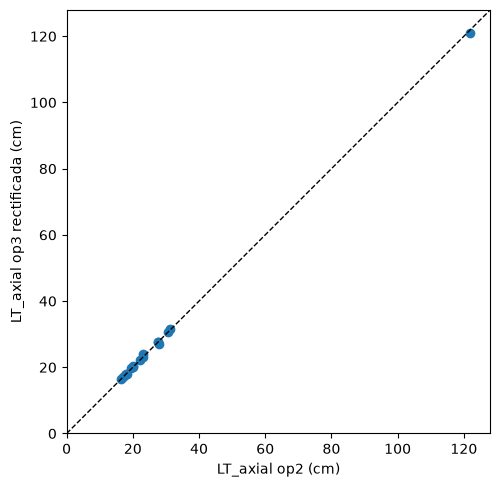

,imagen,pez,LT_axial_cm_op2,LT_axial_cm,dif_axial_cm,dif_axial_pct,LT_recta_cm_op2,LT_recta_cm,cola_doblada
19,mal_angulo.jpg,0.0,121.84,120.84,-1.00,-0.82,118.19,120.83,False
4,example (11).jpg,0.0,28.04,27.18,-0.86,-3.07,26.85,26.83,True
17,example (9).jpg,0.0,23.15,23.90,0.75,3.24,22.75,20.93,False
6,example (11).jpg,2.0,20.08,20.29,0.21,1.04,20.36,20.38,True
13,example (6).jpg,1.0,18.28,18.10,-0.18,-0.96,17.91,17.76,True
5,example (11).jpg,1.0,19.53,19.66,0.13,0.68,19.55,19.55,True
1,example (1).jpg,0.0,31.35,31.42,0.08,0.25,31.29,31.33,False
12,example (6).jpg,0.0,20.09,20.14,0.06,0.29,19.99,20.00,False
10,example (4).jpg,1.0,17.89,17.94,0.05,0.29,17.63,17.69,True
3,example (10).jpg,0.0,17.69,17.66,-0.04,-0.21,17.43,17.07,False


In [7]:
ok = df.dropna(subset=["LT_axial_cm"]).copy()
ok["dif_axial_cm"] = ok["LT_axial_cm"] - ok["LT_axial_cm_op2"]
ok["dif_axial_pct"] = 100 * ok["dif_axial_cm"] / ok["LT_axial_cm_op2"]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = [0, max(ok["LT_axial_cm"].max(), ok["LT_axial_cm_op2"].max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.scatter(ok["LT_axial_cm_op2"], ok["LT_axial_cm"])
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("LT_axial op2 (cm)"); ax.set_ylabel("LT_axial op3 rectificada (cm)"); plt.show()
cols = ["imagen", "pez", "LT_axial_cm_op2", "LT_axial_cm", "dif_axial_cm", "dif_axial_pct", "LT_recta_cm_op2", "LT_recta_cm", "cola_doblada"]
ok.reindex(ok["dif_axial_cm"].abs().sort_values(ascending=False).index)[cols].round(2)

## Mosaico (opción 3)

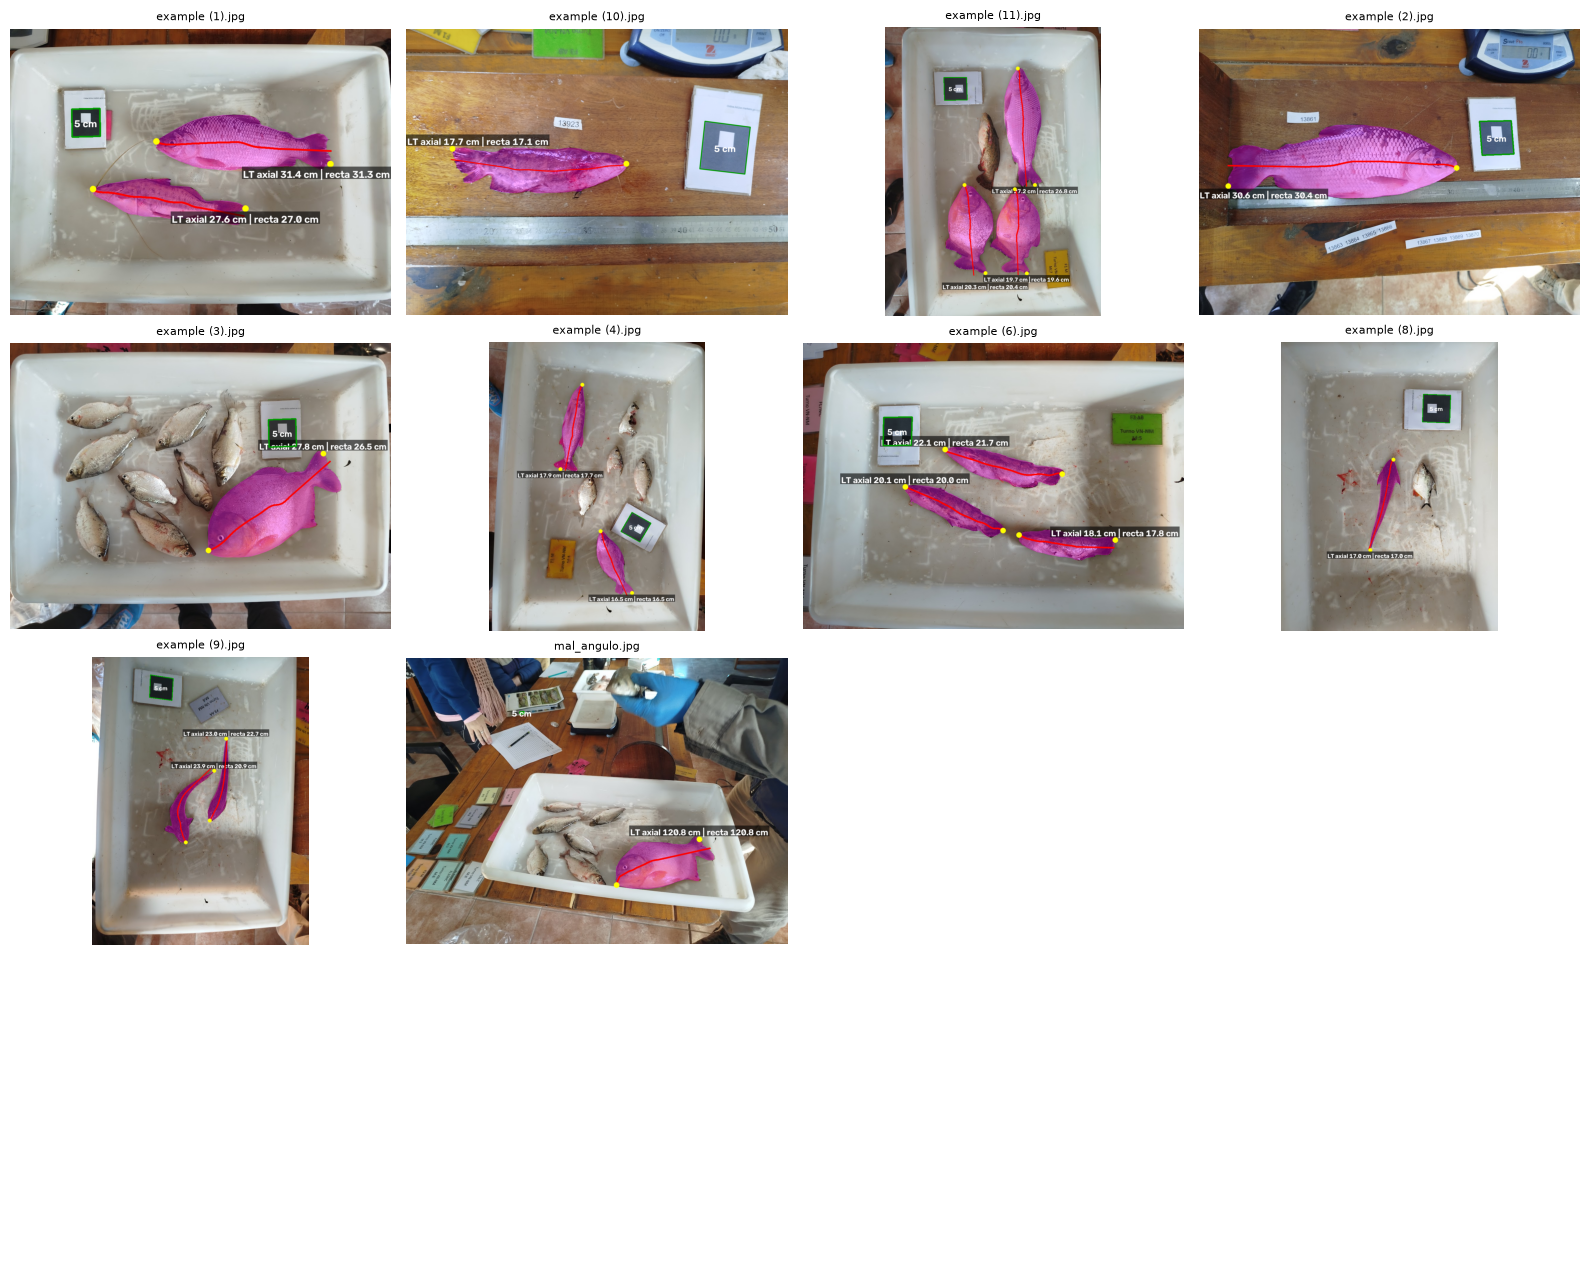

In [8]:
nombres = list(anotadas)
n = 16 if len(nombres) > 9 else 9
lado = 4 if n == 16 else 3
fig, axes = plt.subplots(lado, lado, figsize=(4 * lado, 3.2 * lado))
for a in axes.ravel():
    a.axis("off")
for a, nombre in zip(axes.ravel(), nombres[:n]):
    a.imshow(anotadas[nombre]); a.set_title(nombre, fontsize=8)
plt.tight_layout()
plt.savefig("outputs/mosaico_opcion3.png", dpi=150)
plt.show()

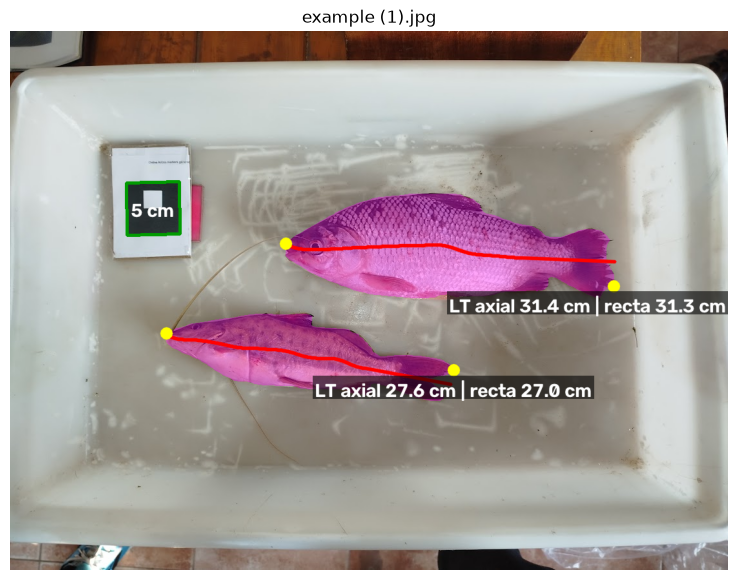

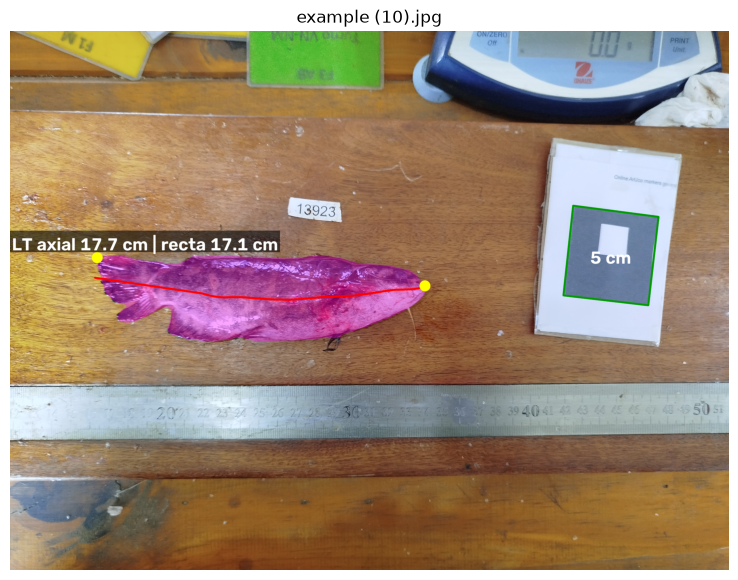

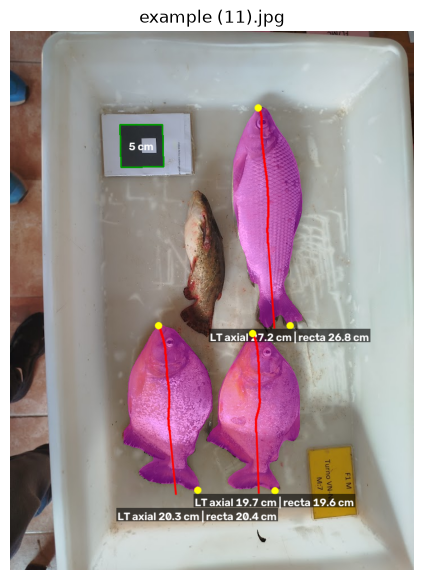

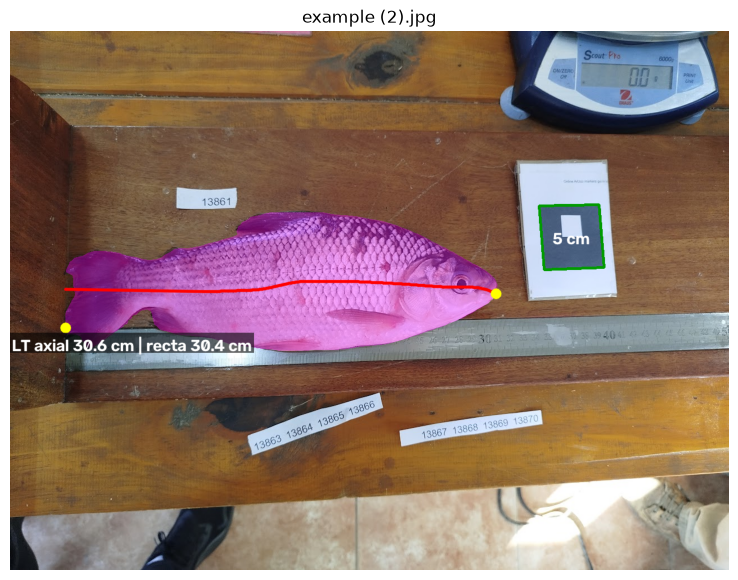

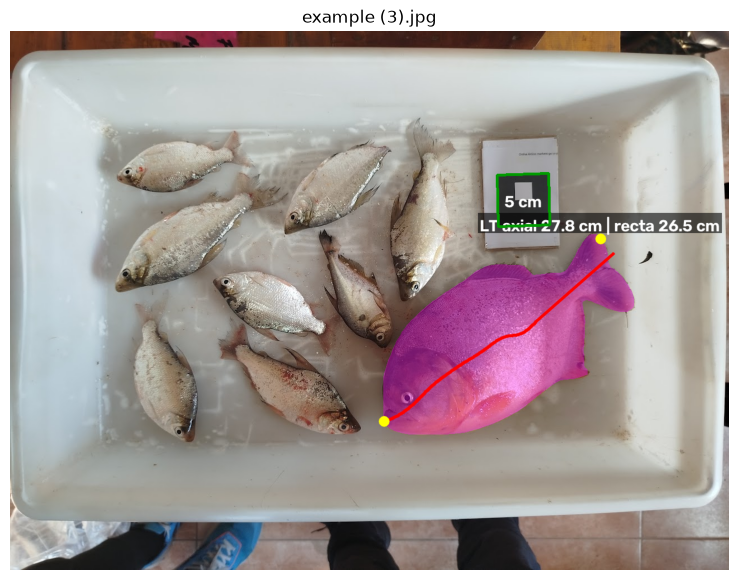

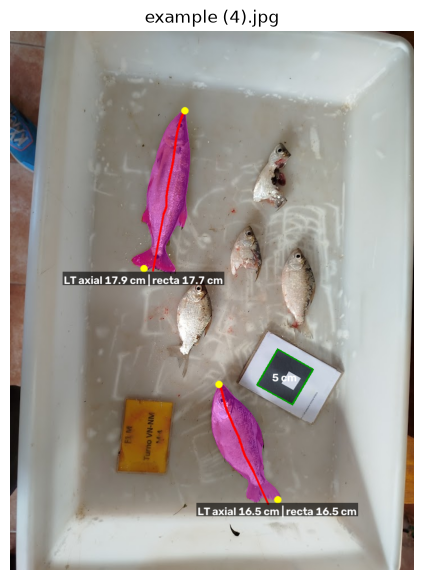

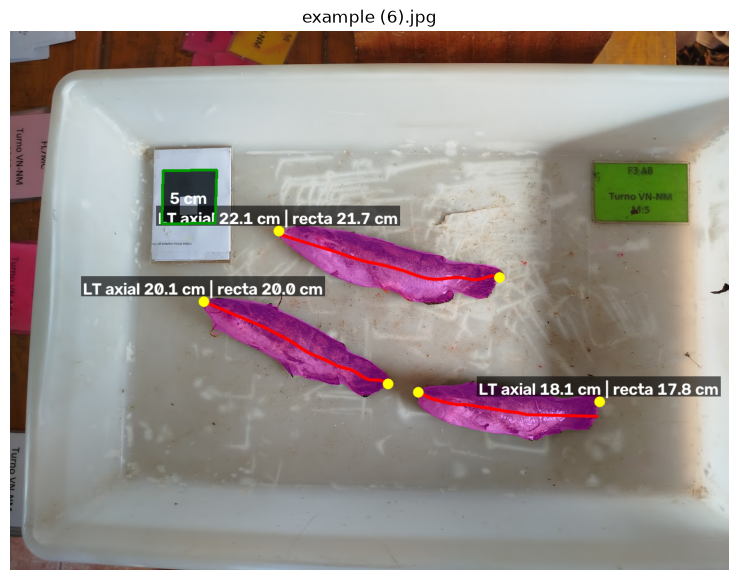

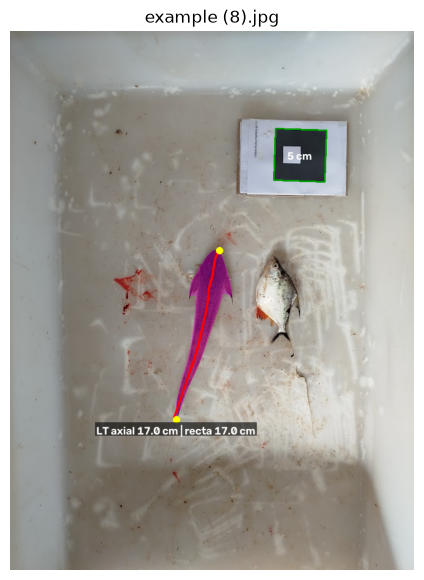

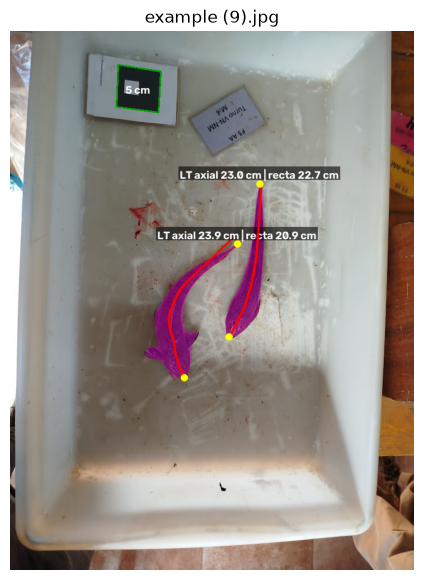

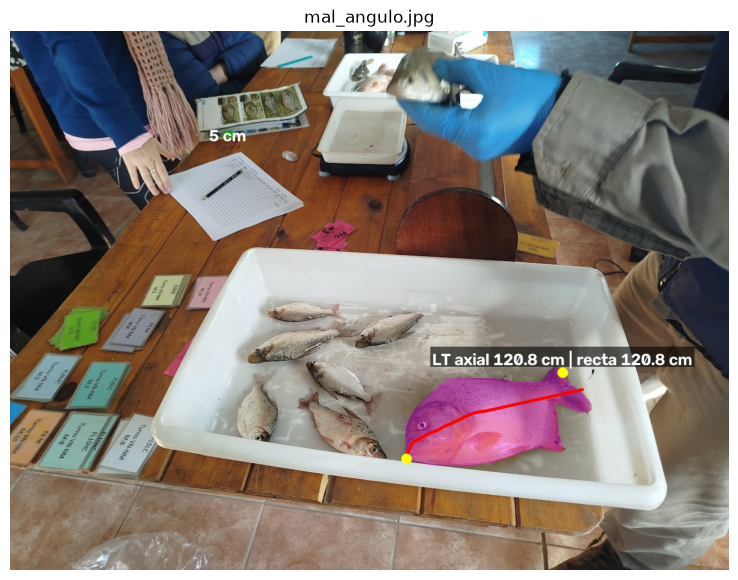

In [9]:
# Vista previa de las primeras imágenes anotadas
for nombre, im in list(anotadas.items())[:]:
    plt.figure(figsize=(10, 7)); plt.imshow(im); plt.title(nombre); plt.axis("off"); plt.show()

## Resumen y limitaciones

**Resultados** (`outputs/resultados_opcion3.csv`, imágenes en `outputs/opcion3/`, mosaico en `outputs/mosaico_opcion3.png`): mismas detecciones que las opciones 1 y 2. Cómputo ~0.1–0.2 s por pez (0.8 s en la imagen de 4000×3000).

**Observaciones**
- En 14 de 16 peces `LT_axial` rectificada difiere <1 % de la opción 2 con homografía (camino en píxeles). Las excepciones son `example (9)` pez 0 (+3.2 %, pez muy curvado) y `example (11)` pez 0 (−3.1 %, marcado `cola_doblada`). Es decir, rectificar la máscara corrige poco más que proyectar los puntos del resultado cuando la perspectiva es moderada; el beneficio crece con la inclinación y con peces curvados.
- `example (2)`: 30.6 cm, consistente con la regla de la foto (~1 a ~31 cm).
- Peces curvados (`example (9)` pez 0): `LT_curva` 24.0 cm vs `LT_recta` 20.9 cm; el axial (23.9) sigue la curvatura del cuerpo.
- Cola doblada: igual que en la opción 2, el axial depende de la dirección del eje y es el resultado menos estable.
- **Limitaciones**: se supone que el pez está en el mismo plano que el ArUco (si el marcador está sobre un papel elevado hay sesgo sistemático); el borde del pez a distinta altura que el marcador no se corrige. `mal_angulo.jpg` sigue dando ~120 cm (la calibración de esa imagen es mala, no es un problema de perspectiva). El valor de `res_px_por_cm` se reduce automáticamente si la máscara rectificada excede `LADO_MAX_PX`.
- No hay medición manual de referencia (`outputs/referencia_manual.csv`), por lo que no se puede afirmar qué variante es más exacta.